# Machine Learning Metrics: Formulas and Python Code | [Link](https://github.com/AdilShamim8/50-Days-of-Machine-Learning/tree/main/Day%2031%20Regression%20Metrics)

Every formula here is paired with code that runs — and each family of metrics is stress-tested where it actually fails in practice: RMSE against a single outlier, accuracy against rare events, ROC-AUC against PR-AUC on the same imbalanced problem, and log loss against overconfidence.

## 1. Regression Metrics

### 1.1. Mean Absolute Error (MAE)
$$
\text{MAE} = \frac{1}{n} \sum_{i=1}^{n} \left| y_i - \hat{y}_i \right|
$$

### 1.2. Mean Squared Error (MSE)
$$
\text{MSE} = \frac{1}{n} \sum_{i=1}^{n} \left( y_i - \hat{y}_i \right)^2
$$

### 1.3. Root Mean Squared Error (RMSE)
$$
\text{RMSE} = \sqrt{\frac{1}{n} \sum_{i=1}^{n} \left( y_i - \hat{y}_i \right)^2}
$$

### 1.4. R-squared (Coefficient of Determination)
$$
R^2 = 1 - \frac{\sum_{i=1}^{n} \left( y_i - \hat{y}_i \right)^2}{\sum_{i=1}^{n} \left( y_i - \bar{y} \right)^2}
$$
where $\bar{y}$ is the mean of $y_i$.

### 1.5. Mean Absolute Percentage Error (MAPE)
$$
\text{MAPE} = \frac{100\%}{n} \sum_{i=1}^{n} \left| \frac{y_i - \hat{y}_i}{y_i} \right|
$$

**All five, implemented from scratch and run** (the same arrays the formulas talk about):

In [1]:
import numpy as np

def mae(y_true, y_pred):
    return np.mean(np.abs(y_true - y_pred))

def mse(y_true, y_pred):
    return np.mean((y_true - y_pred)**2)

def rmse(y_true, y_pred):
    return np.sqrt(mse(y_true, y_pred))

def r2(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred)**2)
    ss_tot = np.sum((y_true - np.mean(y_true))**2)
    return 1 - (ss_res / ss_tot)

def mape(y_true, y_pred):
    return 100 * np.mean(np.abs((y_true - y_pred) / y_true))

y_true = np.array([3, -0.5, 2, 7])
y_pred = np.array([2.5, 0.0, 2, 8])

print("MAE :", round(mae(y_true, y_pred), 3))
print("MSE :", round(mse(y_true, y_pred), 3))
print("RMSE:", round(rmse(y_true, y_pred), 3))
print("R2  :", round(r2(y_true, y_pred), 3))
print("MAPE:", round(mape(y_true, y_pred), 2), "%")

MAE : 0.5
MSE : 0.375
RMSE: 0.612
R2  : 0.949
MAPE: 32.74 %


### 1.6. Where each regression metric bites — measured

The textbook guidance is "RMSE punishes outliers, MAE doesn't." Let's make it concrete: same predictions, plus **one** bad miss — a block predicted at 20 when the truth was 7.

In [2]:
y_true2 = np.append(y_true, 7)
y_pred2 = np.append(y_pred, 20)      # one 13-unit miss

print("without outlier : MAE", round(mae(y_true, y_pred), 3),
      "| RMSE", round(rmse(y_true, y_pred), 3))
print("with one outlier: MAE", round(mae(y_true2, y_pred2), 3),
      "| RMSE", round(rmse(y_true2, y_pred2), 3))

without outlier : MAE 0.5 | RMSE 0.612
with one outlier: MAE 3.0 | RMSE 5.84


**Read-out.** A single 13-unit miss multiplies MAE by **6×** (0.5 → 3.0) but RMSE by **9.5×** (0.612 → 5.840) — squared error lets one point dominate your whole headline number. Choose accordingly: use RMSE when large misses are disproportionately expensive (and you can afford to chase them), MAE when every dollar of error counts the same and you want a robust summary, MAPE when stakeholders think in percentages — **but** remember MAPE is undefined when any true value is 0 and systematically scolds models for over-predicting cheap items. And R²? Its denominator is *your data's* variance: the same model gets a different R² on an easy city and a hard one, and R² < 0 simply means "worse than predicting the mean" — always possible on a holdout.

## 2. Classification Metrics | [Link](https://github.com/AdilShamim8/50-Days-of-Machine-Learning/tree/main/Day%2040%20Classification%20Metrics)

Assume we have four outcomes from a binary classifier:
- True Positives (TP)
- False Positives (FP)
- True Negatives (TN)
- False Negatives (FN)

### 2.1. Accuracy
$$
\text{Accuracy} = \frac{TP + TN}{TP + TN + FP + FN}
$$

### 2.2. Precision
$$
\text{Precision} = \frac{TP}{TP + FP}
$$

### 2.3. Recall (Sensitivity)
$$
\text{Recall} = \frac{TP}{TP + FN}
$$

### 2.4. F1 Score
$$
F1 = 2 \cdot \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}
$$

### 2.5. Python Code Example for Classification Metrics

In [3]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix)

y_true_c = [1, 0, 1, 1, 0, 1, 0, 0, 1, 0]
y_pred_c = [1, 0, 1, 0, 0, 1, 0, 1, 1, 0]

print("Accuracy :", accuracy_score(y_true_c, y_pred_c))
print("Precision:", precision_score(y_true_c, y_pred_c))
print("Recall   :", recall_score(y_true_c, y_pred_c))
print("F1 Score :", f1_score(y_true_c, y_pred_c))
print("Confusion Matrix:\n", confusion_matrix(y_true_c, y_pred_c))

Accuracy : 0.8
Precision: 0.8
Recall   : 0.8
F1 Score : 0.8
Confusion Matrix:
 [[4 1]
 [1 4]]


(4 TP, 1 FP, 1 FN, 4 TN — so precision, recall and F1 all land on 0.8.)

### 2.6. The accuracy paradox — the metric that measures your data, not your model

All the formulas above are true. Here is the trap they set: on data with **1% positives** (fraud, rare diseases, churn-the-week-before-it-happens), *always predicting "no"* scores 99% accuracy. Let's also train a real model with genuine signal and watch what the default threshold does.

In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

rng = np.random.default_rng(42)
n = 10_000
X = rng.normal(size=(n, 10))
y = (rng.uniform(size=n) < 0.01).astype(int)   # 1% rare positives
X[:, 0] += y * 0.8                             # a real, if modest, signal

Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)
proba = LogisticRegression().fit(Xtr, ytr).predict_proba(Xte)[:, 1]
pred = (proba >= 0.5).astype(int)              # the default threshold

print("positives in test set:", yte.sum(), "of", len(yte))
print()
print("DO-NOTHING model (always 'no'):")
print("  accuracy :", round(accuracy_score(yte, np.zeros_like(yte)), 4),
      "| recall: 0.0 | F1: 0.0")
print()
print("REAL model, default threshold 0.5:")
print("  accuracy :", round(accuracy_score(yte, pred), 4))
print("  precision:", precision_score(yte, pred, zero_division=0))
print("  recall   :", recall_score(yte, pred))
print("  F1       :", f1_score(yte, pred, zero_division=0))

positives in test set: 30 of 3000

DO-NOTHING model (always 'no'):
  accuracy : 0.99 | recall: 0.0 | F1: 0.0

REAL model, default threshold 0.5:
  accuracy : 0.99
  precision: 0.0
  recall   : 0.0
  F1       : 0.0


**Read-out.** The real model — which *has* learned something — posts the **same 0.99 accuracy as predicting "no" ten thousand times**, because no single block's probability ever crosses 0.5. Accuracy here measured the **class balance**, not the model. This is not a contrived corner case; it is the default state of fraud, anomaly, and disease screening problems. On imbalanced data, accuracy is not a metric — it is a mirage. Precision, recall, and their tradeoff are the working metrics.

## 3. ROC and AUC Metrics | [Link](https://github.com/AdilShamim8/50-Days-of-Machine-Learning/tree/main/Day%2040%20Classification%20Metrics)

### True Positive Rate (TPR) / Recall
$$
\text{TPR} = \frac{TP}{TP + FN}
$$

### False Positive Rate (FPR)
$$
\text{FPR} = \frac{FP}{FP + TN}
$$

*Note:* The ROC curve plots TPR against FPR at various threshold settings. The AUC (Area Under the Curve) is a single scalar value representing the area under this curve.

**The author's ROC example, executed:**

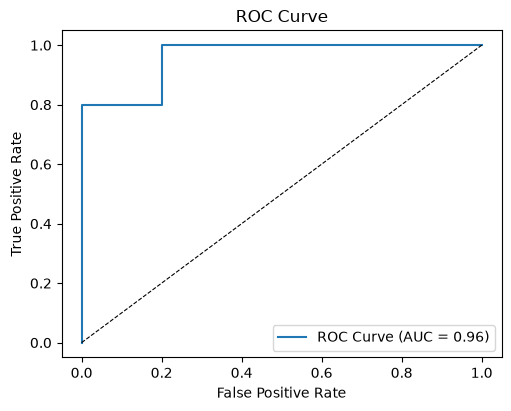

In [5]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

y_prob = [0.9, 0.1, 0.8, 0.4, 0.3, 0.85, 0.2, 0.7, 0.95, 0.05]

fpr, tpr, thresholds = roc_curve(y_true_c, y_prob)
auc = roc_auc_score(y_true_c, y_prob)

plt.figure(figsize=(5, 4), constrained_layout=True)
plt.plot(fpr, tpr, label="ROC Curve (AUC = {:.2f})".format(auc))
plt.plot([0, 1], [0, 1], 'k--', lw=0.8)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

### 3.1. ROC-AUC flatters — Precision-Recall AUC confesses

AUC asks a threshold-free question: *how well does the model rank positives above negatives?* On rare-event data the ranking can be genuinely decent while the practical performance is still thin — because with 1% positives there are so many negatives that even a good FPR sweep looks impressive. The Precision-Recall curve uses precision (which ignores TN, the abundant class) and tells the truth. Both, measured on the same rare-event test split from §2.6:

ROC-AUC  : 0.762   <- 'the model ranks well, looks usable'
PR-AUC(AP): 0.053   <- 'of the alarms you raise, how many are real?'


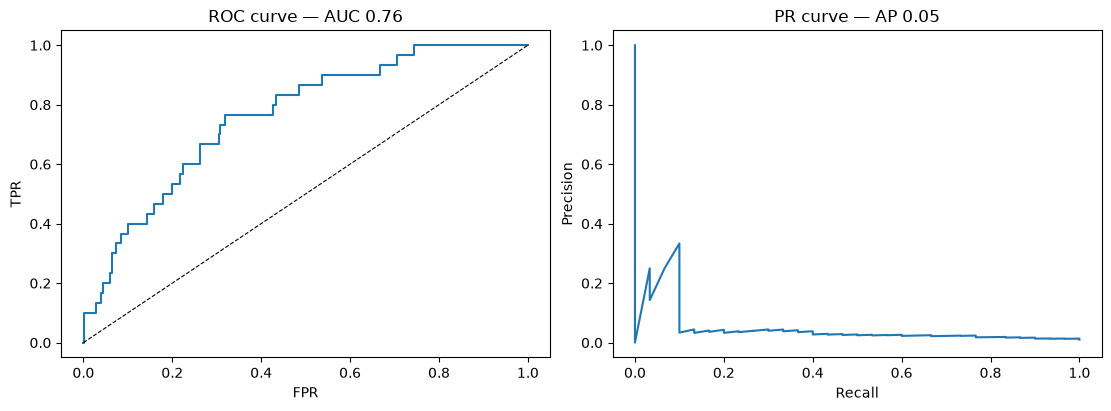

In [6]:
from sklearn.metrics import average_precision_score, precision_recall_curve

roc = roc_auc_score(yte, proba)
pr = average_precision_score(yte, proba)      # area under the PR curve

print(f"ROC-AUC  : {roc:.3f}   <- 'the model ranks well, looks usable'")
print(f"PR-AUC(AP): {pr:.3f}   <- 'of the alarms you raise, how many are real?'")

fpr, tpr, _ = roc_curve(yte, proba)
prec_r, rec_r, _ = precision_recall_curve(yte, proba)

fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
axes[0].plot(fpr, tpr); axes[0].plot([0, 1], [0, 1], 'k--', lw=0.8)
axes[0].set(title=f"ROC curve — AUC {roc:.2f}", xlabel="FPR", ylabel="TPR")
axes[1].plot(rec_r, prec_r)
axes[1].set(title=f"PR curve — AP {pr:.2f}", xlabel="Recall", ylabel="Precision")
plt.show()

**Read-out.** The gap is the whole lesson: **ROC-AUC 0.762** ("usable ranking") against **PR-AUC 0.053** ("when the model raises an alarm, it is right about 5% of the time" — vs the 1% base rate). Neither number is wrong; they answer different questions. An expert reports both — and reaches for PR when positives are scarce.

### 3.2. The threshold dial — precision and recall trade 1-for-1

A classifier is not a verdict; it is a *dial*. Moving the decision threshold is how you spend your error budget — more precision (fewer false alarms) or more recall (fewer misses), never both for free. Sweeping it on the rare-event model:

In [7]:
print(f"{'threshold':>10} {'precision':>10} {'recall':>8} {'F1':>6} {'accuracy':>9}")
for t in [0.02, 0.05, 0.10, 0.5]:
    p = (proba >= t).astype(int)
    print(f"{t:>10.2f} {precision_score(yte, p, zero_division=0):>10.3f} "
          f"{recall_score(yte, p):>8.3f} {f1_score(yte, p, zero_division=0):>6.3f} "
          f"{accuracy_score(yte, p):>9.3f}")

 threshold  precision   recall     F1  accuracy
      0.02      0.042    0.300  0.074     0.925
      0.05      0.200    0.033  0.057     0.989
      0.10      0.000    0.000  0.000     0.990


      0.50      0.000    0.000  0.000     0.990


**Read-out.** At `t=0.02` the model catches **30%** of rare events but only **4.2%** of its alarms are real (still 4× better than guessing); at `t=0.05` precision rises to **20%** and recall falls to **3.3%**; at the default 0.5 it predicts nothing at all. There is no "best" threshold in the abstract — the right setting depends on what a miss costs versus what an alarm costs. That decision belongs to the business, informed by exactly this table.

## 4. Log Loss (Binary Cross-Entropy Loss) | [Link](https://github.com/AdilShamim8/50-Days-of-Machine-Learning/tree/main/Day%2040%20Classification%20Metrics)

$$
\text{Log Loss} = -\frac{1}{n} \sum_{i=1}^{n} \left[ y_i \log(\hat{p}_i) + (1 - y_i) \log(1 - \hat{p}_i) \right]
$$

where $\hat{p}_i$ is the predicted probability for the positive class.

Log loss is the only metric in this note that grades **calibration** — not *what* you predicted, but *how confidently*. Two models can both be wrong once; log loss treats them very differently:

In [8]:
from sklearn.metrics import log_loss

confident_wrong = log_loss([1], [0.01], labels=[0, 1])   # said "1% chance" — it happened
uncertain_wrong = log_loss([1], [0.49], labels=[0, 1])   # said "49% chance" — it happened

print("confidently wrong (p=0.01, truth=1):", round(confident_wrong, 3))
print("uncertainly wrong  (p=0.49, truth=1):", round(uncertain_wrong, 3))

confidently wrong (p=0.01, truth=1): 4.605
uncertainly wrong  (p=0.49, truth=1): 0.713


**Read-out.** The confident wrong prediction costs **4.605**, the uncertain one **0.713** — being wrong at 99% confidence costs 6.5× more than being wrong at 51%. This is the metric (as the training objective) that teaches models to say "I'm not sure," and the metric (at evaluation time) that punishes exactly the overconfidence that accuracy, precision, and recall never see.

## 5. Which metric, when — the working summary

| Situation | Reach for | Because |
|---|---|---|
| Regression, large misses disproportionately costly | RMSE | squares the pain |
| Regression, errors are dollars and outliers exist | MAE | robust, same units everywhere |
| Regression, stakeholders think in % | MAPE | interpretable — but undefined at y=0 |
| Classification, classes balanced | Accuracy, F1 | accuracy means something here |
| Classification, positives rare (fraud, screening) | PR-AUC, precision/recall at tuned thresholds | accuracy is a mirage; ROC-AUC flatters |
| Choosing between probability models / calibration matters | Log loss | grades confidence, punishes overconfidence |

**The meta-rule:** pick the metric *before* the model — from the cost of each error type, not from whatever `model.score()` returns.